# Experiment A — Part 2: final combined preprocessing

Compare untreated baseline with the ordered six-technique pipeline: **intensity normalization → grayscale → NonLocalMeans denoising → deskew → CLAHE → size normalization**. The original four stages retain their relative order; intensity normalization is added first and resizing last. This order is fixed before inference, not selected from test scores. Individual validation-optimal parameters do not imply an optimal combination.

Use the **exact same 250 IAM and 250 Bentham test lines** and pinned model/processor/decoding settings as completed Part 1. Restore dataset-specific active settings from its frozen protocol: IAM denoising h=7, deskew ±5°/0.5°, CLAHE clip1/grid8x8; Bentham h=1, deskew ±10°/0.25°, CLAHE clip2/grid16x16. Both resize to height 128 with proportional width/LANCZOS. Other denoising parameters remain h_color=3, template=7, search=21. Grayscale and global min-max normalization have no numeric parameters.

No training, parameter search or order tuning. This is the final combined-treatment evaluation on fixed test subsets, not the complete test partitions. Source references, model settings, ordered stages and configurations are recorded before inference. Baseline remains a control even where individual validation treatments did not improve accuracy.

Bentham RGBA is composited onto white equally for baseline and combined processing; originals are preserved. Text normalization collapses whitespace, retaining case/punctuation. Corpus CER/WER aggregate edit counts rather than averaging line rates. Mandatory TrOCR RGB conversion, resize and normalization follow optional preprocessing. Since grayscale precedes denoising, h_color is inactive in this combination. Parts 1 and 3 remain unchanged.

In [1]:
from pathlib import Path
import sys
import json
import platform
import hashlib
import random
import shutil
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans,
    Deskew, CLAHE, IntensityNormalization, SizeNormalization)
from src.validation.denoising import adapt_image, evaluate
from src.evaluation.recognition import corpus_metrics
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
PART1 = ROOT / "results/test/experiment_a/20261112T024202644804Z"
reference = json.loads((PART1 / "metadata.json").read_text())
assert json.loads((PART1 / "status.json").read_text())["status"] == "complete"
SPLIT, SAMPLE_COUNT = "test", 250
SEED = reference["seed"]
BATCH_SIZE = 8
DATASET_REVISION = reference["datasets"]["iam"]["revision"]
CHECKPOINT = reference["model"]["checkpoint"]
MODEL_REVISION = reference["model"]["revision"]
DEVICE = reference["model"]["device"]
GENERATION = reference["model"]["generation_kwargs"]
ORDER = ("intensity_normalization", "grayscale", "denoising", "deskew", "clahe", "size_normalization")
pipelines_by_dataset, parameter_rows = {}, []
for dataset_name in ("iam", "bentham"):
    saved = reference["preprocessing"][dataset_name]
    nlm, deskew, clahe, size = [saved[name]["steps"][0] for name in ("denoising", "deskew", "clahe", "size_normalization")]
    steps = {
        "intensity_normalization": IntensityNormalization(),
        "grayscale": Grayscale(),
        "denoising": NonLocalMeans(**{key: nlm[key] for key in ("h", "h_color", "template_window_size", "search_window_size")}),
        "deskew": Deskew(max_angle=deskew["max_angle"], angle_step=deskew["angle_step"]),
        "clahe": CLAHE(clip_limit=clahe["clip_limit"], tile_grid_size=tuple(clahe["tile_grid_size"])),
        "size_normalization": SizeNormalization(target_height=size["target_height"]),
    }
    for name, step in steps.items():
        assert json.loads(json.dumps(step.to_config())) == saved[name]["steps"][0]
        parameter_rows.append({"dataset": dataset_name, "technique": name,
            "parameters": json.dumps(step.to_config())})
    pipelines_by_dataset[dataset_name] = {
        "baseline": PreprocessingPipeline(),
        "combined": PreprocessingPipeline(tuple(steps[name] for name in ORDER)),
    }
pipeline_names = ["baseline", "combined"]
frozen_config = {dataset_name: {name: pipe.to_config() for name, pipe in pipes.items()}
                 for dataset_name, pipes in pipelines_by_dataset.items()}
config_digest = hashlib.sha256(json.dumps(frozen_config, sort_keys=True).encode()).hexdigest()
assert reference["split"] == SPLIT and reference["sample_count_per_dataset"] == SAMPLE_COUNT
assert reference["datasets"]["bentham"]["revision"] == REVISION
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Fixed order:", " → ".join(ORDER))
display(pd.DataFrame(parameter_rows))
print("Frozen configuration SHA-256:", config_digest)

Fixed order: intensity_normalization → grayscale → denoising → deskew → clahe → size_normalization


,dataset,technique,parameters
0,iam,intensity_normalization,"{""name"": ""intensity_normalization"", ""enabled"":..."
1,iam,grayscale,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
2,iam,denoising,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
3,iam,deskew,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."
4,iam,clahe,"{""name"": ""clahe"", ""enabled"": true, ""clip_limit..."
5,iam,size_normalization,"{""name"": ""size_normalization"", ""enabled"": true..."
6,bentham,intensity_normalization,"{""name"": ""intensity_normalization"", ""enabled"":..."
7,bentham,grayscale,"{""name"": ""grayscale"", ""enabled"": true, ""output..."
8,bentham,denoising,"{""name"": ""non_local_means"", ""enabled"": true, ""..."
9,bentham,deskew,"{""name"": ""deskew"", ""enabled"": true, ""max_angle..."


Frozen configuration SHA-256: d3e89d139220c4d2b35ff14e2fe7bf269e6d11264e7b7fcb9aea3cfeb1c1ede7


In [3]:
datasets = {"iam": load_iam_dataset(split=SPLIT, revision=DATASET_REVISION),
            "bentham": load_bentham_dataset(split=SPLIT)}
indices_by_dataset = reference["sample_indices"]
selected, samples_by_dataset, sample_rows = {}, {}, []
for dataset_name, dataset in datasets.items():
    assert dataset._fingerprint == reference["datasets"][dataset_name]["fingerprint"]
    indices = indices_by_dataset[dataset_name]
    assert len(indices) == len(set(indices)) == 250
    subset = dataset.select(indices)
    if dataset_name == "iam":
        subset = subset.add_column("id", [f"sample_{i}" for i in indices])
    assert subset._fingerprint == reference["datasets"][dataset_name]["selected_fingerprint"]
    selected[dataset_name] = subset
    samples = []
    for index, row in zip(indices, subset):
        assert isinstance(row["text"], str) and row["text"].strip()
        image = adapt_image(row["image"])
        sample = {"id": row["id"], "image": image, "ground_truth": row["text"]}
        samples.append(sample)
        sample_rows.append({"dataset": dataset_name, "sample_id": row["id"],
            "dataset_index": index, "source_mode": row["image"].mode, "mode": image.mode,
            "width": image.width, "height": image.height, "ground_truth": row["text"]})
    assert len({s["id"] for s in samples}) == 250
    samples_by_dataset[dataset_name] = samples
sample_info = pd.DataFrame(sample_rows)
print("Test split sizes:", {name: len(ds) for name, ds in datasets.items()})
display(sample_info.groupby(["dataset", "source_mode", "mode"]).size().rename("selected_lines").to_frame())
display(sample_info.groupby("dataset").head(2))

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Test split sizes: {'iam': 2915, 'bentham': 860}


,,,selected_lines
dataset,source_mode,mode,
bentham,RGBA,RGB,250
iam,L,L,250


,dataset,sample_id,dataset_index,source_mode,mode,width,height,ground_truth
0,iam,sample_11,11,L,L,959,128,round a doll's house .
1,iam,sample_18,18,L,L,2209,128,such as a chair and a motor-car . The idea is ...
250,bentham,096_028_001_01_03,2,RGBA,RGB,1573,154,in paving the way to the consideration of
251,bentham,096_028_001_01_06,5,RGBA,RGB,1607,145,much time in explaining the nature &


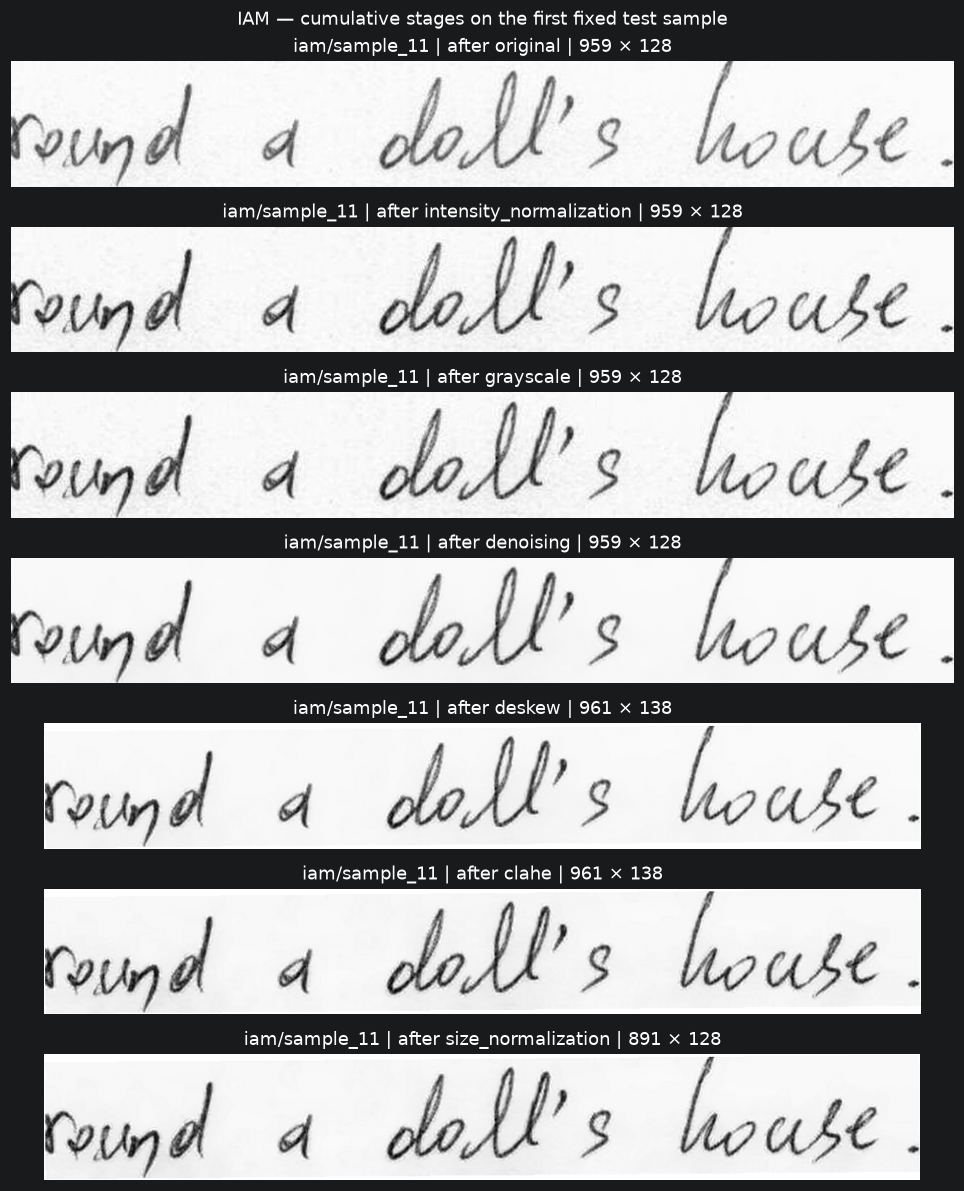

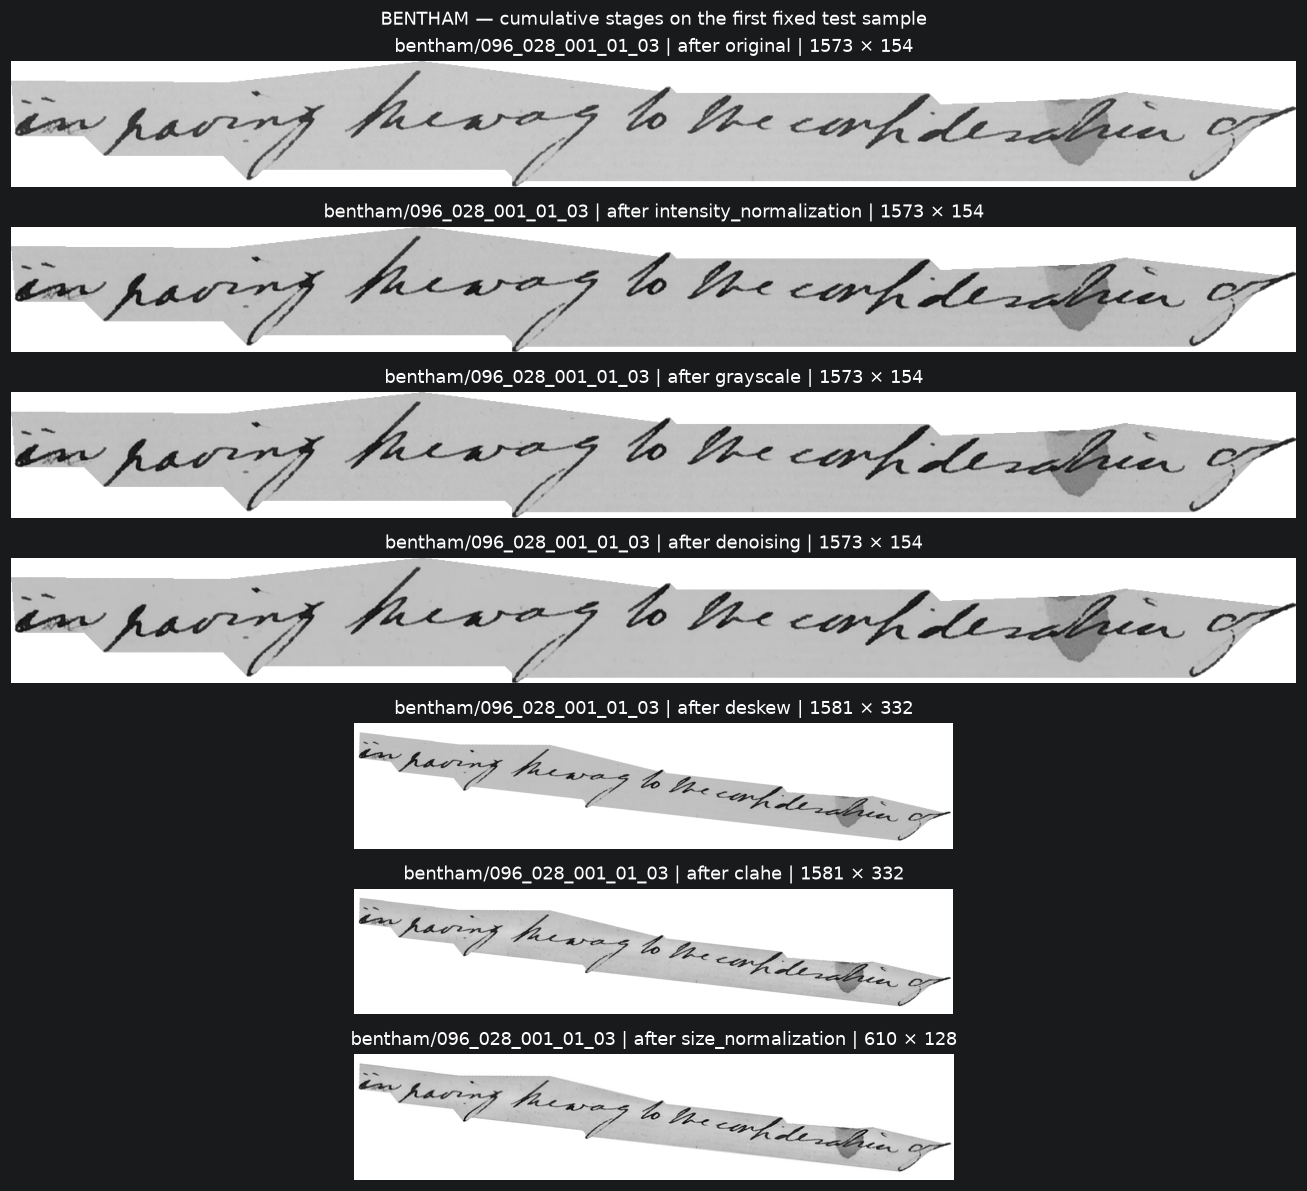

In [4]:
stage_preview_figures = {}
for dataset_name in selected:
    sample = samples_by_dataset[dataset_name][0]
    combined = pipelines_by_dataset[dataset_name]["combined"]
    stage_names = ["original"] + list(ORDER)
    fig, axes = plt.subplots(len(stage_names), 1, figsize=(15, 11), squeeze=False)
    for i, stage_name in enumerate(stage_names):
        image = PreprocessingPipeline(combined.steps[:i])(sample["image"])
        axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[i, 0].set_title(f"{dataset_name}/{sample['id']} | after {stage_name} | {image.width} × {image.height}")
        axes[i, 0].axis("off")
    fig.suptitle(f"{dataset_name.upper()} — cumulative stages on the first fixed test sample")
    fig.tight_layout()
    stage_preview_figures[dataset_name] = fig
    plt.show()

## Recognition and saved artifacts

Load the pinned model once and warm up outside timings. Reuse Part 1 baseline predictions only after checking sample fingerprint, count, pipeline, batch size, normalization and full model identity; the shared evaluator also verifies their signed identity. Record the source of reused predictions. Evaluate the two combined pipelines freshly.

Save protocol and sample manifests before inference under results/test/experiment_a_part_2/<UTC-run-id>/. Checkpoint each batch and rerun only the inference cell to resume in this kernel. Timings exclude model loading and warm-up and are descriptive. No test-based configuration changes follow this run.

In [5]:
if "run_dir" not in globals() or "results/test/experiment_a_part_2" not in run_dir.as_posix():
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = ROOT / "results/test/experiment_a_part_2" / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "experiment": "Experiment A Part 2: combined treatment", "phase": "final_test", "split": SPLIT,
        "sample_count_per_dataset": SAMPLE_COUNT, "seed": SEED, "batch_size": BATCH_SIZE,
        "sample_indices": indices_by_dataset, "part1_reference": str(PART1.relative_to(ROOT)),
        "selection": "dataset-specific active parameters frozen in Part 1 from validation CER then WER",
        "validation_selections": reference["validation_selections"],
        "selection_studies": reference["selection_studies"],
        "preprocessing": frozen_config, "preprocessing_order": list(ORDER),
        "frozen_configuration_sha256": config_digest, "datasets": reference["datasets"],
        "bentham_archive_sha256": ARCHIVES,
        "normalization": "collapse whitespace; retain case and punctuation",
        "input_adaptation": "RGBA white composite; preserve L/RGB",
        "python": platform.python_version(), "platform": platform.platform(),
        "versions": {p: version(p) for p in ("torch", "transformers", "datasets", "huggingface-hub",
            "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
    }
    sample_info.to_csv(run_dir / "samples.csv", index=False)
    pd.DataFrame(parameter_rows).to_csv(run_dir / "frozen_parameters.csv", index=False)
    (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    (run_dir / "status.json").write_text(json.dumps({"status": "running", "expected_dataset_configuration_pairs": 4}))
saved_protocol = json.loads((run_dir / "metadata.json").read_text())
assert saved_protocol["frozen_configuration_sha256"] == config_digest
assert saved_protocol["sample_indices"] == indices_by_dataset
assert config_digest == hashlib.sha256(json.dumps({ds: {name: pipe.to_config() for name, pipe in pipes.items()}
    for ds, pipes in pipelines_by_dataset.items()}, sort_keys=True).encode()).hexdigest()
if "model" not in globals():
    model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION, device=DEVICE, generation_kwargs=GENERATION)
    _ = model.predict(samples_by_dataset["iam"][0]["image"])
assert json.loads(json.dumps(model.to_config())) == reference["model"]
metadata["model"] = model.to_config()
summaries = []
for name in pipeline_names:
    for dataset_name, dataset in selected.items():
        pipeline = pipelines_by_dataset[dataset_name][name]
        folder = run_dir / dataset_name / name
        if name == "baseline" and not folder.exists():
            source = PART1 / dataset_name / name
            identity = json.loads((source / "identity.json").read_text())
            assert identity["dataset_fingerprint"] == dataset._fingerprint and identity["count"] == SAMPLE_COUNT
            assert identity["transform"] == pipeline.to_config() and identity["batch_size"] == BATCH_SIZE
            assert identity["model"] == json.loads(json.dumps(model.to_config()))
            assert identity["normalization"] == "collapse whitespace; preserve case/punctuation"
            assert identity["input_adaptation"] == "RGBA white composite; preserve L/RGB"
            shutil.copytree(source, folder)
            metadata.setdefault("reused_baseline_sources", {})[dataset_name] = str(source.relative_to(ROOT))
        (run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
        result = evaluate(dataset, dataset_name, model, name, pipeline, run_dir, BATCH_SIZE)
        summaries.append(result)
        pd.DataFrame(summaries).to_csv(run_dir / "partial_summary.csv", index=False)
        print(result, flush=True)
summary = pd.DataFrame(summaries)
assert len(summary) == 4 and summary.sample_count.eq(250).all()
for metric in ("cer", "wer"):
    base = summary[summary.configuration == "baseline"].set_index("dataset")[metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - summary.dataset.map(base))
    summary[f"{metric}_relative_change_pct"] = 100 * (summary[metric] / summary.dataset.map(base) - 1)
summary["total_seconds"] = summary.preprocessing_seconds + summary.inference_seconds
summary["seconds_per_line"] = summary.total_seconds / summary.sample_count
frames = []
for dataset_name in selected:
    for name in pipeline_names:
        frame = pd.read_csv(run_dir / dataset_name / name / "predictions.csv", keep_default_na=False)
        assert frame.sample_id.tolist() == [s["id"] for s in samples_by_dataset[dataset_name]]
        frames.append(frame.assign(dataset=dataset_name, configuration=name))
predictions = pd.concat(frames, ignore_index=True)
summary.to_csv(run_dir / "summary.csv", index=False)
predictions.to_csv(run_dir / "predictions.csv", index=False)
for dataset_name, fig in stage_preview_figures.items():
    fig.savefig(run_dir / f"{dataset_name}_preprocessing_stages.png", bbox_inches="tight")
(run_dir / "status.json").write_text(json.dumps({"status": "inference_complete", "completed_dataset_configuration_pairs": 4}))
print("Saved:", run_dir)
display(summary)

W1111 22:06:53.015000 22895 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.04776260009420631, 'wer': 0.10812023328847016, 'preprocessing_seconds': 0.007902452001872007, 'inference_seconds': 75.54761058299846}
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 250, 'cer': 0.16121244635193133, 'wer': 0.428854734754586, 'preprocessing_seconds': 0.09649438100677799, 'inference_seconds': 70.62097046100462}
iam/combined: 8/250
iam/combined: 80/250
iam/combined: 160/250
iam/combined: 240/250
iam/combined: 250/250
{'dataset': 'iam', 'configuration': 'combined', 'sample_count': 250, 'cer': 0.04983513895430994, 'wer': 0.11395244504262, 'preprocessing_seconds': 16.812962707992483, 'inference_seconds': 76.37208454299434}
bentham/combined: 8/250
bentham/combined: 80/250
bentham/combined: 160/250
bentham/combined: 240/250
bentham/combined: 250/250
{'dataset': 'bentham', 'configuration': 'combined', 'sample_count': 250, 'cer': 0.15236051502145923, 'wer': 0.4189390183440754, 'prepr

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,total_seconds,seconds_per_line
0,iam,baseline,250,0.047763,0.108120,0.007902,75.547611,0.000000,0.000000,0.000000,0.000000,75.555513,0.302222
1,bentham,baseline,250,0.161212,0.428855,0.096494,70.620970,0.000000,0.000000,0.000000,0.000000,70.717465,0.282870
2,iam,combined,250,0.049835,0.113952,16.812963,76.372085,0.207254,4.339250,0.583221,5.394191,93.185047,0.372740
3,bentham,combined,250,0.152361,0.418939,24.247779,70.186714,-0.885193,-5.490849,-0.991572,-2.312139,94.434493,0.377738


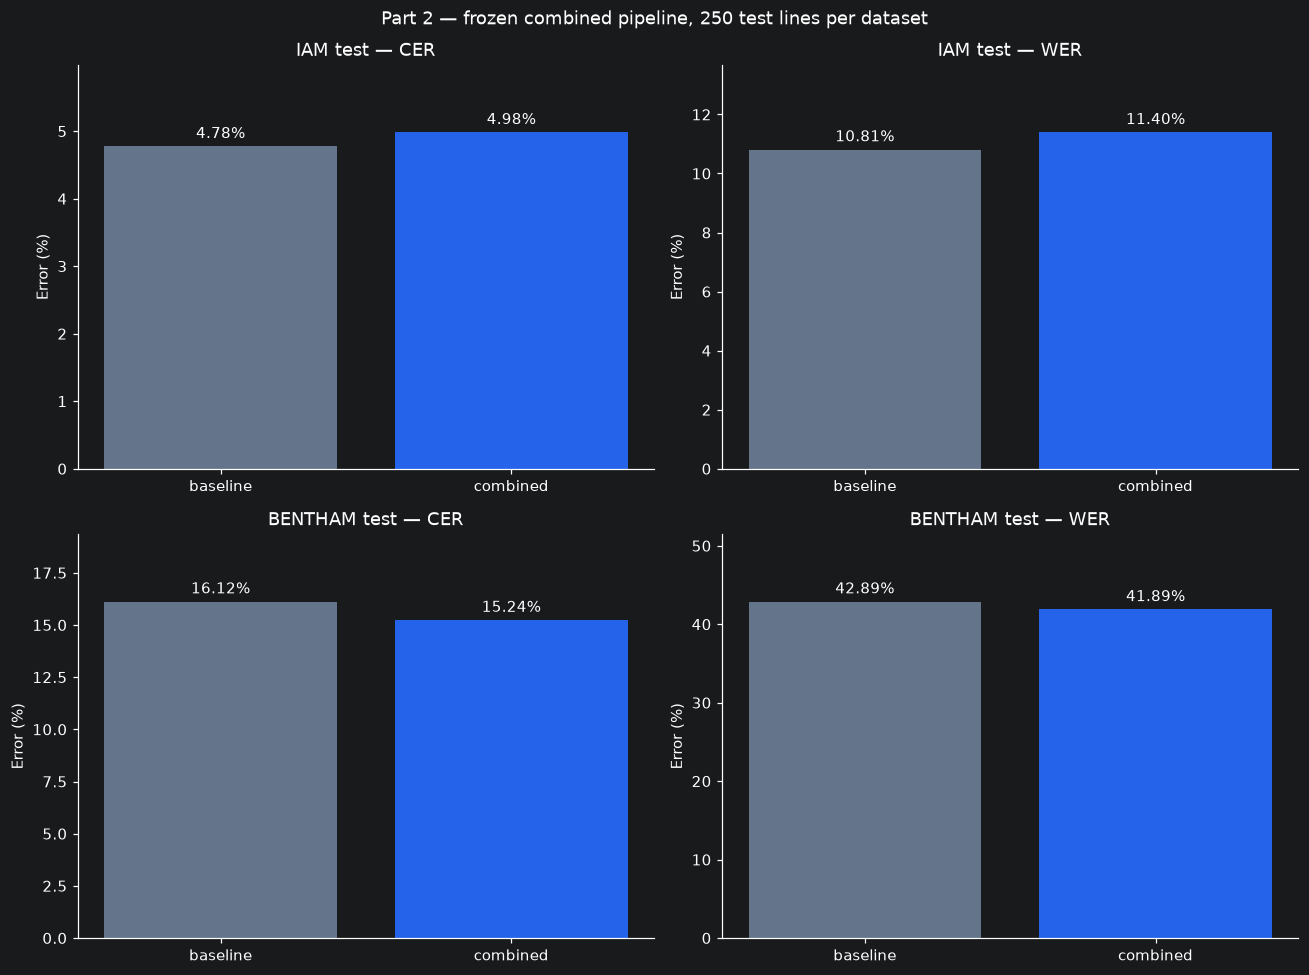

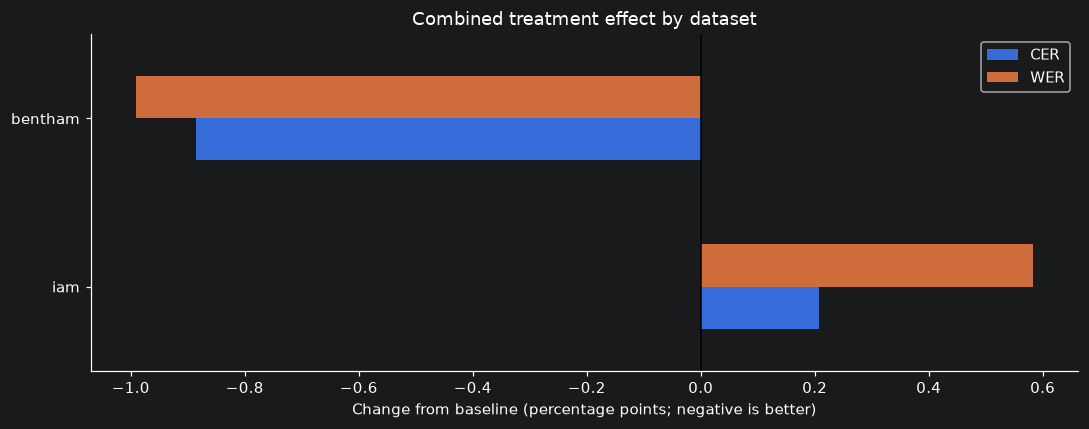

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, dataset_name in enumerate(selected):
    current = summary[summary.dataset == dataset_name].set_index("configuration").loc[pipeline_names]
    for col, metric in enumerate(("cer", "wer")):
        values = 100 * current[metric]
        bars = axes[row, col].bar(current.index, values, color=["#64748b", "#2563eb"])
        axes[row, col].bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3)
        axes[row, col].set(title=f"{dataset_name.upper()} test — {metric.upper()}", ylabel="Error (%)")
        axes[row, col].margins(y=.2)
fig.suptitle("Part 2 — frozen combined pipeline, 250 test lines per dataset")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()
changes = summary[summary.configuration == "combined"].set_index("dataset")[["cer_change_pp", "wer_change_pp"]]
ax = changes.rename(columns={"cer_change_pp": "CER", "wer_change_pp": "WER"}).plot.barh(figsize=(10, 4))
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Change from baseline (percentage points; negative is better)", ylabel="", title="Combined treatment effect by dataset")
plt.tight_layout()
plt.savefig(run_dir / "corpus_changes.png", bbox_inches="tight")
plt.show()

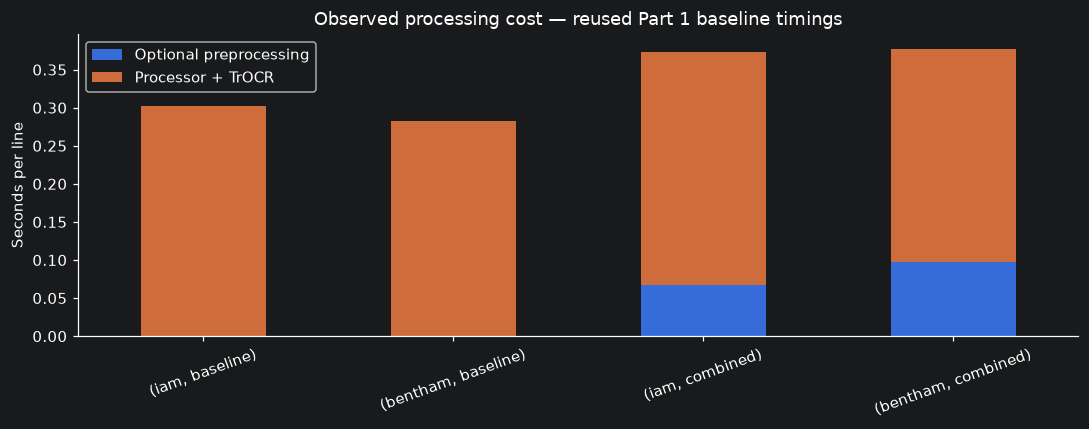

In [7]:
timing = summary.set_index(["dataset", "configuration"])[["preprocessing_seconds", "inference_seconds"]].div(
    summary.set_index(["dataset", "configuration"])["sample_count"], axis=0)
ax = timing.rename(columns={"preprocessing_seconds": "Optional preprocessing",
    "inference_seconds": "Processor + TrOCR"}).plot.bar(stacked=True, figsize=(10, 4), rot=20)
ax.set(xlabel="", ylabel="Seconds per line", title="Observed processing cost — reused Part 1 baseline timings")
plt.tight_layout()
plt.savefig(run_dir / "processing_time.png", bbox_inches="tight")
plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

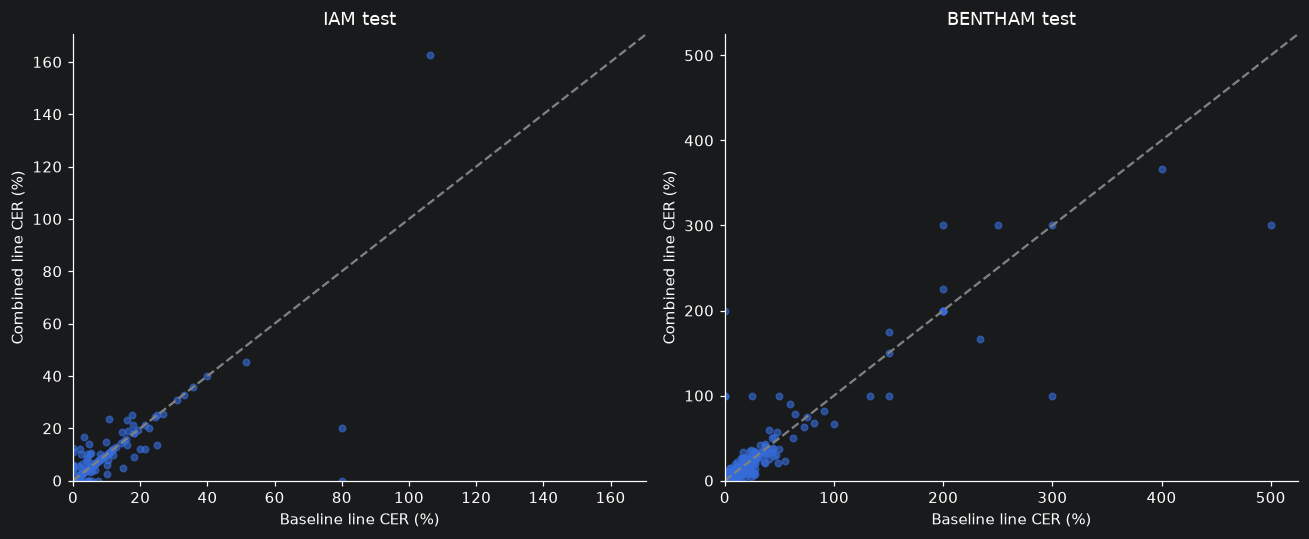

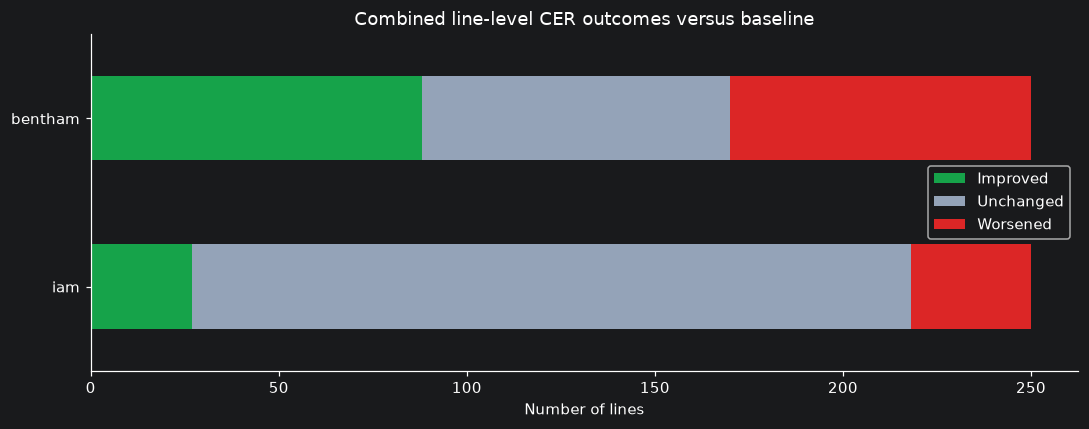

,Improved,Unchanged,Worsened
dataset,,,
iam,27,191,32
bentham,88,82,80


In [8]:
paired_by_dataset, outcome_rows = {}, []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, dataset_name in zip(axes, selected):
    paired = predictions[predictions.dataset == dataset_name].pivot(index="sample_id", columns="configuration", values="cer")
    paired_by_dataset[dataset_name] = paired
    x, y = 100 * paired["baseline"], 100 * paired["combined"]
    limit = max(float(x.max()), float(y.max()), 1) * 1.05
    ax.scatter(x, y, alpha=.6, s=18)
    ax.plot([0, limit], [0, limit], "--", color="gray")
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline line CER (%)", ylabel="Combined line CER (%)",
        title=f"{dataset_name.upper()} test")
    delta = paired["combined"] - paired["baseline"]
    same = np.isclose(delta, 0, atol=1e-12, rtol=0)
    outcome_rows.append({"dataset": dataset_name, "Improved": int(((delta < 0) & ~same).sum()),
        "Unchanged": int(same.sum()), "Worsened": int(((delta > 0) & ~same).sum())})
fig.tight_layout()
fig.savefig(run_dir / "paired_line_cer.png", bbox_inches="tight")
plt.show()
outcomes = pd.DataFrame(outcome_rows).set_index("dataset")
ax = outcomes.plot.barh(stacked=True, color=["#16a34a", "#94a3b8", "#dc2626"], figsize=(10, 4))
ax.set(xlabel="Number of lines", ylabel="", title="Combined line-level CER outcomes versus baseline")
plt.tight_layout()
plt.savefig(run_dir / "line_outcomes.png", bbox_inches="tight")
plt.show()
outcomes.to_csv(run_dir / "line_outcomes.csv")
display(outcomes)

iam/sample_798 | CER change -80.00 pp
Reference: darkness .
Baseline: at a business .
Combined: darkness .
iam/sample_1669 | CER change +56.25 pp
Reference: trans-economic .
Baseline: transuming a recession in C.
Combined: transuming in a Belgian crisis i. c.


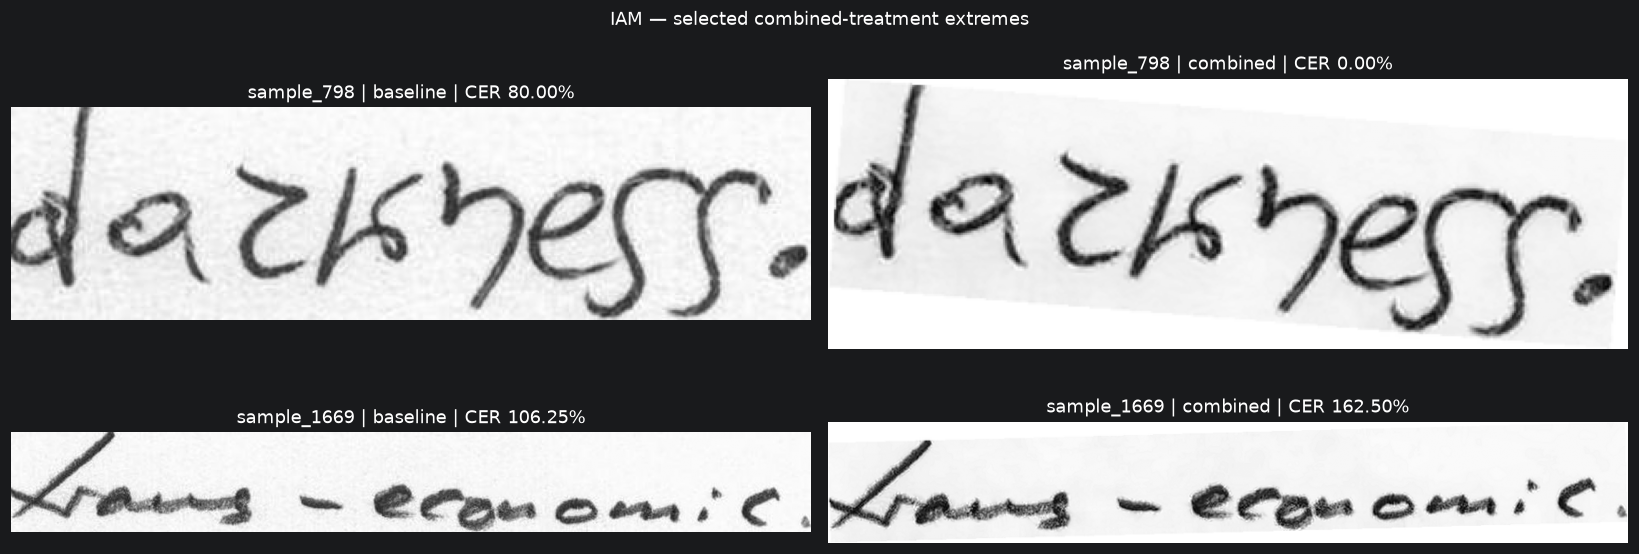

bentham/072_049_002_01_01 | CER change -200.00 pp
Reference: C 
Baseline: c.i
Combined: C.
bentham/035_327_001_02_23 | CER change +200.00 pp
Reference: 1 
Baseline: 1
Combined: 1 .


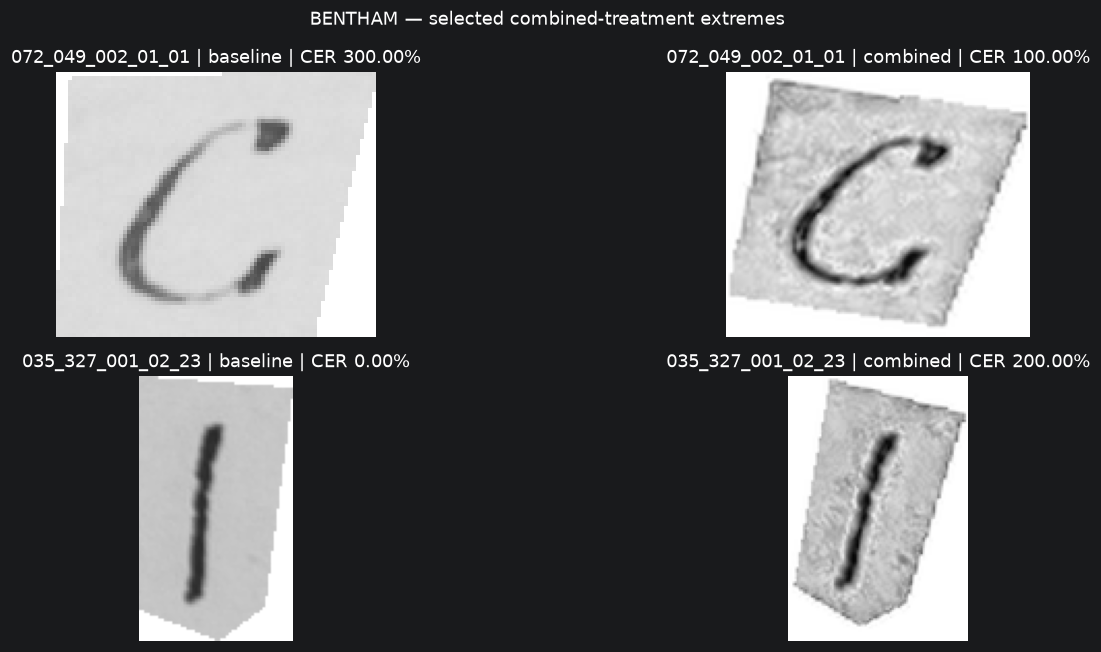

In [9]:
# Deliberately selected CER-change extremes, not representative examples.
for dataset_name in selected:
    paired = paired_by_dataset[dataset_name]
    sample_by_id = {s["id"]: s for s in samples_by_dataset[dataset_name]}
    lookup = predictions[predictions.dataset == dataset_name].set_index(["sample_id", "configuration"])
    delta = paired["combined"] - paired["baseline"]
    example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
    fig, axes = plt.subplots(len(example_ids), 2, figsize=(15, 3 * len(example_ids)), squeeze=False)
    for row, sample_id in enumerate(example_ids):
        sample = sample_by_id[sample_id]
        for col, name in enumerate(pipeline_names):
            image = pipelines_by_dataset[dataset_name][name](sample["image"])
            axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
            axes[row, col].set_title(f"{sample_id} | {name} | CER {100 * paired.loc[sample_id, name]:.2f}%")
            axes[row, col].axis("off")
        print(f"{dataset_name}/{sample_id} | CER change {100 * delta.loc[sample_id]:+.2f} pp")
        print("Reference:", sample["ground_truth"])
        print("Baseline:", lookup.loc[(sample_id, "baseline"), "prediction"])
        print("Combined:", lookup.loc[(sample_id, "combined"), "prediction"])
    fig.suptitle(f"{dataset_name.upper()} — selected combined-treatment extremes")
    fig.tight_layout()
    fig.savefig(run_dir / f"{dataset_name}_examples_combined.png", bbox_inches="tight")
    plt.show()

## Final comparison: IAM and Bentham

The final tables compare baseline with the fixed combined treatment separately for each dataset, followed by a side-by-side view. Negative changes mean lower error. The additional Part 1 comparison places the combination alongside the individual techniques on the exact same test images and model settings. It is descriptive; do not use it to tune a new pipeline on these test scores.

This measures the full ordered pipeline and cannot isolate stage contributions or establish the best order. Individually selected parameters may interact unfavorably in combination. Source datasets and model-domain coverage differ; absolute accuracy differences are not solely effects of preprocessing. Selected image examples are diagnostic extremes. Timings describe the observed machine and run, with reused baseline timings, and are not a speed benchmark.

In [10]:
assert len(predictions) == 1000
assert json.loads((run_dir / "metadata.json").read_text())["frozen_configuration_sha256"] == config_digest
for (dataset_name, name), rows in predictions.groupby(["dataset", "configuration"]):
    assert len(rows) == 250
    measured = corpus_metrics(rows.ground_truth.tolist(), rows.prediction.tolist())
    recorded = summary[(summary.dataset == dataset_name) & (summary.configuration == name)].iloc[0]
    assert all(np.isclose(measured[metric], recorded[metric], atol=1e-12, rtol=0) for metric in ("cer", "wer"))
assert outcomes.sum(axis=1).eq(250).all()
final_results = summary.assign(cer_pct=100 * summary.cer, wer_pct=100 * summary.wer)
for dataset_name in ("iam", "bentham"):
    print(f"{dataset_name.upper()} — FINAL TEST RESULTS (250 lines)")
    display(final_results[final_results.dataset == dataset_name][
        ["configuration", "sample_count", "cer_pct", "wer_pct", "cer_change_pp", "wer_change_pp"]].round(4))
both_datasets = final_results.pivot(index="configuration", columns="dataset", values=["cer_pct", "wer_pct"]).reindex(pipeline_names)
print("Both datasets — corpus error rates (%)")
display(both_datasets.round(4))
both_datasets.to_csv(run_dir / "final_results_both_datasets.csv")
part1_summary = pd.read_csv(PART1 / "summary.csv")
individual_and_combined = pd.concat([part1_summary.assign(experiment="Part 1"),
    summary[summary.configuration == "combined"].assign(experiment="Part 2")], ignore_index=True)
comparison = individual_and_combined.assign(cer_pct=lambda x: 100*x.cer, wer_pct=lambda x: 100*x.wer).pivot(
    index="configuration", columns="dataset", values=["cer_pct", "wer_pct"])
print("Individual techniques and combined treatment — same fixed test subsets")
display(comparison.round(4))
comparison.to_csv(run_dir / "part1_and_part2_comparison.csv")
(run_dir / "status.json").write_text(json.dumps({"status": "complete", "split": "test",
    "samples_per_dataset": 250, "completed_dataset_configuration_pairs": 4}, indent=2))
print("Results:", run_dir)

IAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
0,baseline,250,4.7763,10.8120,0.0000,0.0000
2,combined,250,4.9835,11.3952,0.2073,0.5832


BENTHAM — FINAL TEST RESULTS (250 lines)


,configuration,sample_count,cer_pct,wer_pct,cer_change_pp,wer_change_pp
1,baseline,250,16.1212,42.8855,0.0000,0.0000
3,combined,250,15.2361,41.8939,-0.8852,-0.9916


Both datasets — corpus error rates (%)


cer_pct          wer_pct         
dataset        bentham     iam  bentham      iam
configuration                                   
baseline       16.1212  4.7763  42.8855  10.8120
combined       15.2361  4.9835  41.8939  11.3952

Individual techniques and combined treatment — same fixed test subsets


cer_pct          wer_pct         
dataset                  bentham     iam  bentham      iam
configuration                                             
baseline                 16.1212  4.7763  42.8855  10.8120
clahe                    14.7353  4.6538  40.7536  10.8569
combined                 15.2361  4.9835  41.8939  11.3952
denoising                16.2375  4.6161  42.5384  10.4980
deskew                   16.9617  4.7668  43.8275  10.7672
grayscale                16.1212  4.7763  42.8855  10.8120
intensity_normalization  15.6563  4.6350  42.4888  10.8120
size_normalization       16.1570  4.7763  42.7863  10.8120

Results: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/test/experiment_a_part_2/20261112T030651144026Z
